# Small Business Profitability Analysis
**Project ID:** DA-019  
**Domain:** Business Analytics  

### Objective:
Analyze sales, costs, discounts, and product categories to understand profitability patterns and identify which products or periods generate stronger profit margins.


### 1. Import Libraries


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8


### 2. Load and Inspect Dataset
We load the retail transactions dataset (`small_business_sales.csv`) which contains sales, product pricing, discount rates, and order statuses.


In [2]:
# Load dataset
data_path = os.path.join("..", "data", "small_business_sales.csv")
df_raw = pd.read_csv(data_path)

print(f"Dataset Shape: {df_raw.shape}")
df_raw.head()


Dataset Shape: (1400, 12)


In [3]:
# Check column types and missing values
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    1400 non-null   str    
 1   Date              1400 non-null   str    
 2   Product_ID        1400 non-null   str    
 3   Product_Name      1400 non-null   str    
 4   Category          1400 non-null   str    
 5   Unit_Cost         1400 non-null   float64
 6   Unit_Price        1400 non-null   float64
 7   Units_Sold        1400 non-null   int64  
 8   Discount_Percent  1400 non-null   int64  
 9   Payment_Method    1400 non-null   str    
 10  Customer_Segment  1400 non-null   str    
 11  Return_Status     1400 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 243.7 KB


### 3. Data Cleaning & Feature Extraction
- Check for duplicates and handle missing values.
- Convert date column to datetime and extract month and quarter.
- Categorize discount percentages into standard tiers for easier analysis.


In [4]:
df = df_raw.copy()

# Remove any duplicate transactions
df = df.drop_duplicates(subset=['Transaction_ID'])

# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')
df['Quarter'] = 'Q' + df['Date'].dt.quarter.astype(str)

# Create discount buckets
bins = [-1, 0, 10, 20, 30, 100]
labels = ['No Discount (0%)', 'Low (1-10%)', 'Moderate (11-20%)', 'High (21-30%)', 'Deep (>30%)']
df['Discount_Bracket'] = pd.cut(df['Discount_Percent'], bins=bins, labels=labels)

df[['Transaction_ID', 'Date', 'Month_Name', 'Discount_Bracket', 'Return_Status']].head()


### 4. Financial Calculations
> **Note:** Revenue is not profit. Profit is calculated after deducting product cost (COGS) and accounting for discounts and returns.

**Formulas used:**
1. Gross Revenue = $\text{Unit Price} \times \text{Units Sold}$
2. Discount Amount = $\text{Gross Revenue} \times (\text{Discount Percent} / 100)$
3. Net Revenue = $\text{Gross Revenue} - \text{Discount Amount}$ (0 if returned)
4. Total COGS = $\text{Unit Cost} \times \text{Units Sold}$ (0 if returned and restocked)
5. Net Profit = $\text{Net Revenue} - \text{Total COGS}$
6. Profit Margin (%) = $(\text{Net Profit} / \text{Net Revenue}) \times 100$


In [5]:
# Calculate calculated columns
df['Gross_Revenue'] = (df['Unit_Price'] * df['Units_Sold']).round(2)
df['Discount_Amount'] = (df['Gross_Revenue'] * (df['Discount_Percent'] / 100.0)).round(2)

# If an order is returned, Net Revenue is 0
df['Net_Revenue'] = np.where(
    df['Return_Status'] == 'Yes',
    0.0,
    df['Gross_Revenue'] - df['Discount_Amount']
).round(2)

# COGS is 0 for returned orders because goods are restocked
df['Total_COGS'] = np.where(
    df['Return_Status'] == 'Yes',
    0.0,
    df['Unit_Cost'] * df['Units_Sold']
).round(2)

# Net Profit
df['Net_Profit'] = (df['Net_Revenue'] - df['Total_COGS']).round(2)

# Profit Margin %
df['Profit_Margin_Pct'] = np.where(
    df['Net_Revenue'] > 0,
    (df['Net_Profit'] / df['Net_Revenue']) * 100.0,
    0.0
).round(2)

df[['Transaction_ID', 'Unit_Price', 'Units_Sold', 'Gross_Revenue', 'Net_Revenue', 'Total_COGS', 'Net_Profit', 'Profit_Margin_Pct']].head()


In [6]:
# Overall Summary
valid_sales = df[df['Return_Status'] == 'No']

summary = pd.DataFrame({
    'Metric': [
        'Total Transactions',
        'Successful Sales',
        'Returned Orders',
        'Total Net Revenue (₹)',
        'Total COGS (₹)',
        'Total Net Profit (₹)',
        'Overall Profit Margin (%)'
    ],
    'Value': [
        f"{len(df):,}",
        f"{len(valid_sales):,}",
        f"{(df['Return_Status'] == 'Yes').sum()}",
        f"₹{valid_sales['Net_Revenue'].sum():,.2f}",
        f"₹{valid_sales['Total_COGS'].sum():,.2f}",
        f"₹{valid_sales['Net_Profit'].sum():,.2f}",
        f"{(valid_sales['Net_Profit'].sum() / valid_sales['Net_Revenue'].sum()) * 100:.2f}%"
    ]
})

summary


### 5. Category-wise Profitability Comparison
Comparing performance across categories to see if higher revenue leads to higher profit.


In [7]:
category_perf = valid_sales.groupby('Category').agg(
    Orders=('Transaction_ID', 'count'),
    Units_Sold=('Units_Sold', 'sum'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Total_COGS=('Total_COGS', 'sum'),
    Net_Profit=('Net_Profit', 'sum')
).reset_index()

category_perf['Margin_Pct'] = (category_perf['Net_Profit'] / category_perf['Net_Revenue'] * 100).round(2)
category_perf = category_perf.sort_values(by='Net_Profit', ascending=False).reset_index(drop=True)
category_perf


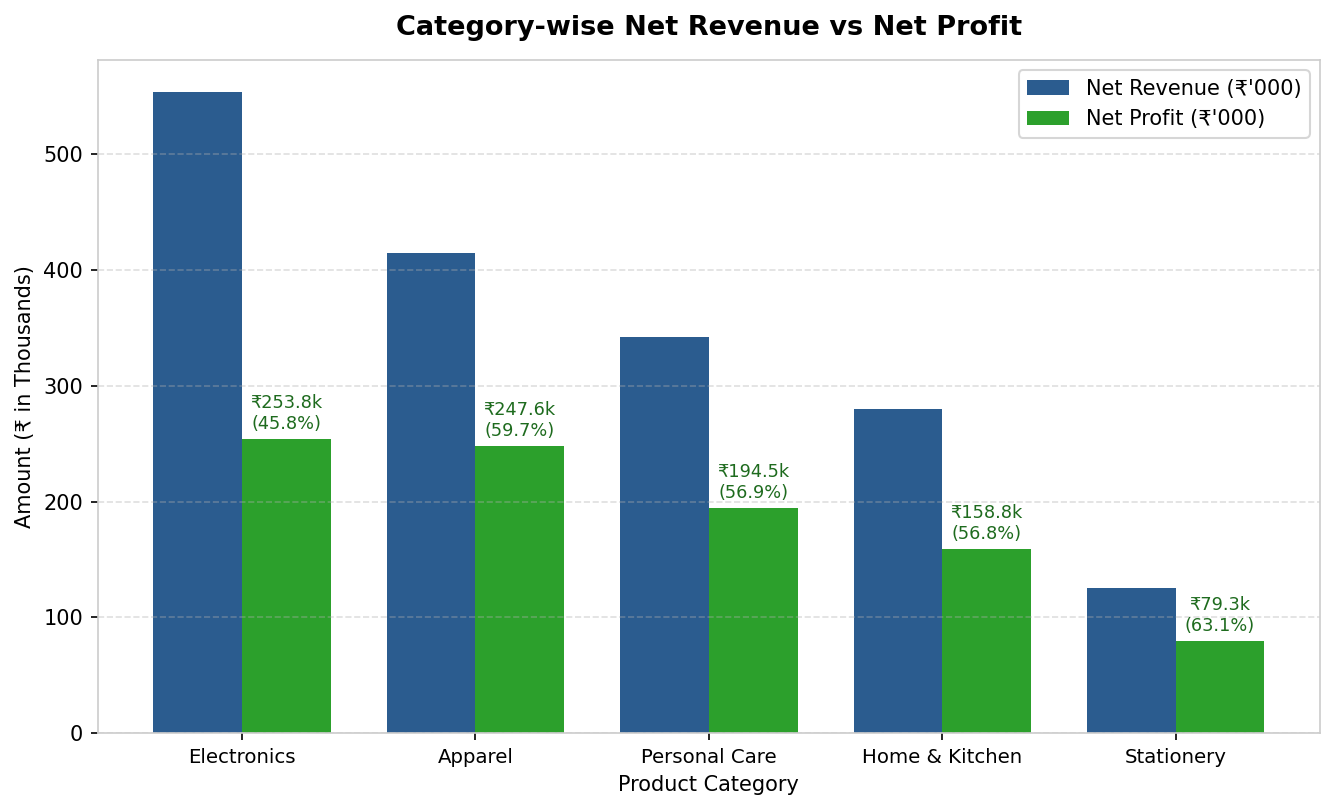

In [8]:
# Chart 1: Category-wise Net Revenue vs Net Profit
categories = category_perf['Category'].tolist()
rev_k = category_perf['Net_Revenue'] / 1000.0
prof_k = category_perf['Net_Profit'] / 1000.0

x = np.arange(len(categories))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)

ax.bar(x - width/2, rev_k, width, label="Net Revenue (₹'000)", color="#2b5c8f")
rects2 = ax.bar(x + width/2, prof_k, width, label="Net Profit (₹'000)", color="#2ca02c")

ax.set_title("Category-wise Net Revenue vs Net Profit", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Product Category", fontsize=10)
ax.set_ylabel("Amount (₹ in Thousands)", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=9.5)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

for i, rect in enumerate(rects2):
    height = rect.get_height()
    margin = category_perf['Margin_Pct'].iloc[i]
    ax.annotate(f"₹{height:.1f}k\n({margin:.1f}%)",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center", va="bottom", fontsize=8.5, color="#1e6b1e")

plt.tight_layout()
plt.show()


### 6. Discount Impact on Profit Margin
Analyzing how giving discounts affects the business profit margin.


In [9]:
discount_summary = valid_sales.groupby('Discount_Bracket', observed=False).agg(
    Orders=('Transaction_ID', 'count'),
    Total_Revenue=('Net_Revenue', 'sum'),
    Total_COGS=('Total_COGS', 'sum'),
    Total_Profit=('Net_Profit', 'sum')
).reset_index()

discount_summary['Realized_Margin_Pct'] = (discount_summary['Total_Profit'] / discount_summary['Total_Revenue'] * 100).round(2)
discount_summary


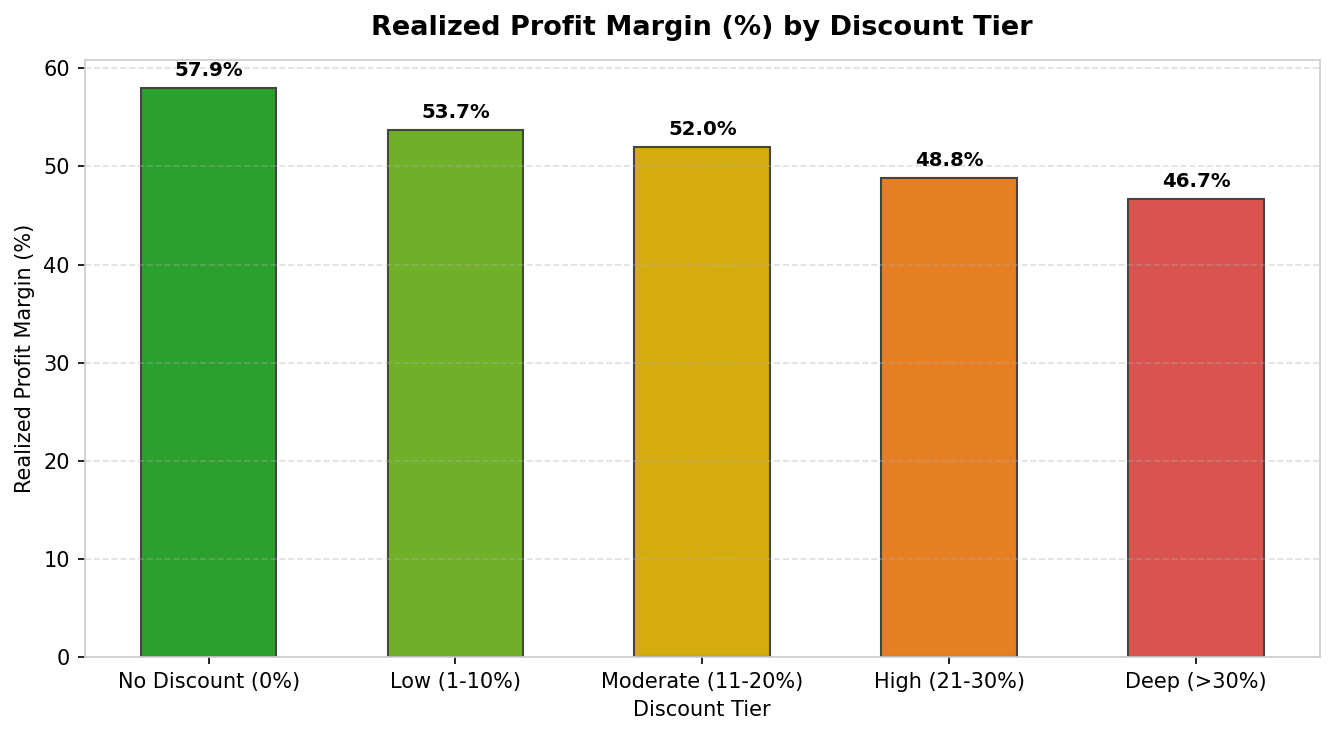

In [10]:
# Chart 3: Realized Profit Margin (%) by Discount Tier
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

brackets = discount_summary['Discount_Bracket'].astype(str)
margins = discount_summary['Realized_Margin_Pct']
colors = ["#2ca02c", "#70b028", "#d4ac0d", "#e67e22", "#d9534f"]

bars = ax.bar(brackets, margins, color=colors, width=0.55, edgecolor="#444444")

ax.set_title("Realized Profit Margin (%) by Discount Tier", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Discount Tier", fontsize=10)
ax.set_ylabel("Realized Profit Margin (%)", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()


### 7. Monthly Revenue & Profit Trends
Evaluating monthly performance to spot seasonal patterns and lean months.


In [11]:
monthly_perf = valid_sales.groupby('Month').agg(
    Month_Name=('Month_Name', 'first'),
    Orders=('Transaction_ID', 'count'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Net_Profit=('Net_Profit', 'sum')
).reset_index().sort_values('Month')

monthly_perf['Margin_Pct'] = (monthly_perf['Net_Profit'] / monthly_perf['Net_Revenue'] * 100).round(2)
monthly_perf[['Month_Name', 'Orders', 'Net_Revenue', 'Net_Profit', 'Margin_Pct']]


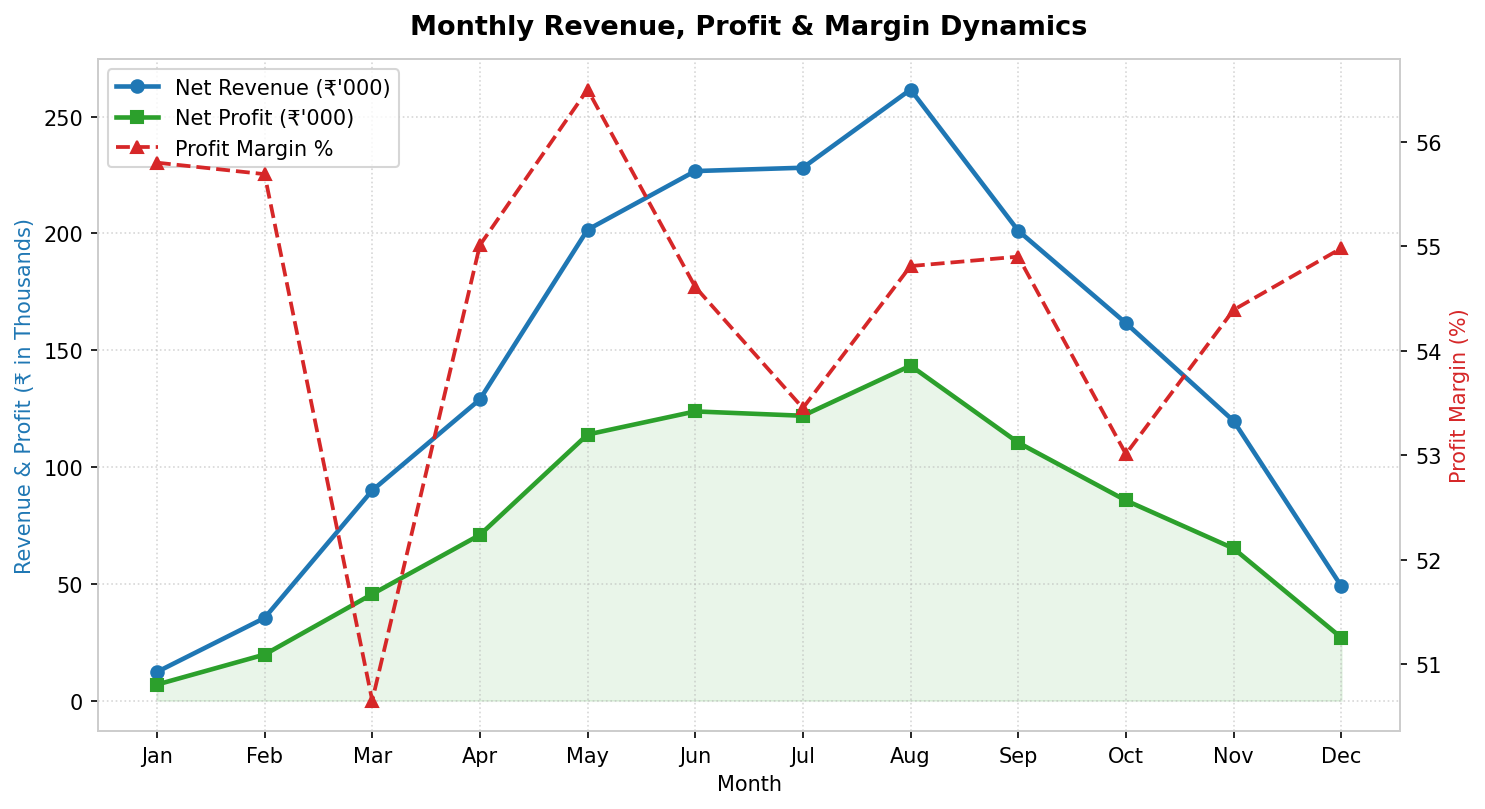

In [12]:
# Chart 2: Monthly Revenue, Profit & Margin Dynamics
fig, ax1 = plt.subplots(figsize=(10, 5.5), dpi=150)
ax2 = ax1.twinx()

months = monthly_perf['Month_Name']
rev_k = monthly_perf['Net_Revenue'] / 1000.0
prof_k = monthly_perf['Net_Profit'] / 1000.0

line1 = ax1.plot(months, rev_k, color="#1f77b4", marker="o", linewidth=2.2, label="Net Revenue (₹'000)")
line2 = ax1.plot(months, prof_k, color="#2ca02c", marker="s", linewidth=2.2, label="Net Profit (₹'000)")
ax1.fill_between(months, prof_k, color="#2ca02c", alpha=0.1)

line3 = ax2.plot(months, monthly_perf['Margin_Pct'], color="#d62728", linestyle="--", marker="^", linewidth=1.8, label="Profit Margin %")

ax1.set_title("Monthly Revenue, Profit & Margin Dynamics", fontsize=13, fontweight="bold", pad=12)
ax1.set_xlabel("Month", fontsize=10)
ax1.set_ylabel("Revenue & Profit (₹ in Thousands)", fontsize=10, color="#1f77b4")
ax2.set_ylabel("Profit Margin (%)", fontsize=10, color="#d62728")

ax1.grid(True, linestyle=":", alpha=0.5)

lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

plt.tight_layout()
plt.show()


### 8. Product Portfolio Rankings (Top 5 vs Bottom 5)
Identifying which products deliver strong margins and which ones have weaker margins.


In [13]:
prod_perf = valid_sales.groupby(['Product_ID', 'Product_Name', 'Category']).agg(
    Units_Sold=('Units_Sold', 'sum'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Net_Profit=('Net_Profit', 'sum')
).reset_index()

prod_perf['Margin_Pct'] = (prod_perf['Net_Profit'] / prod_perf['Net_Revenue'] * 100).round(2)
prod_perf = prod_perf.sort_values(by='Margin_Pct', ascending=False).reset_index(drop=True)

print("--- Top 5 Products by Margin ---")
display(prod_perf.head(5))

print("\n--- Bottom 5 Products by Margin ---")
display(prod_perf.tail(5))


--- Top 5 Products by Margin ---
  Product_ID                         Product_Name       Category  Units_Sold  Net_Revenue  Net_Profit  Margin_Pct
0   APPR-005      Cushioned Sports Socks (3-Pack)        Apparel          79      19554.6    13638.13       69.74
1   STAT-004         Pastel Sticky Notes (4-Pack)     Stationery         114      12971.0     8969.63       69.15
2   STAT-002  Retractable Gel Pen Set (Pack of 5)     Stationery         117      16822.1    11566.67       68.76
3   STAT-005          Fluorescent Highlighter Set     Stationery         114      17490.0    11756.38       67.22
4   CARE-003    Nourishing Shea Butter Hand Cream  Personal Care         146      33888.9    22137.17       65.32

--- Bottom 5 Products by Margin ---
   Product_ID                   Product_Name       Category  Units_Sold  Net_Revenue  Net_Profit  Margin_Pct
20   CARE-004      Sonic Electric Toothbrush  Personal Care         139    167571.00    90962.52       54.28
21   ELEC-001         Wirele

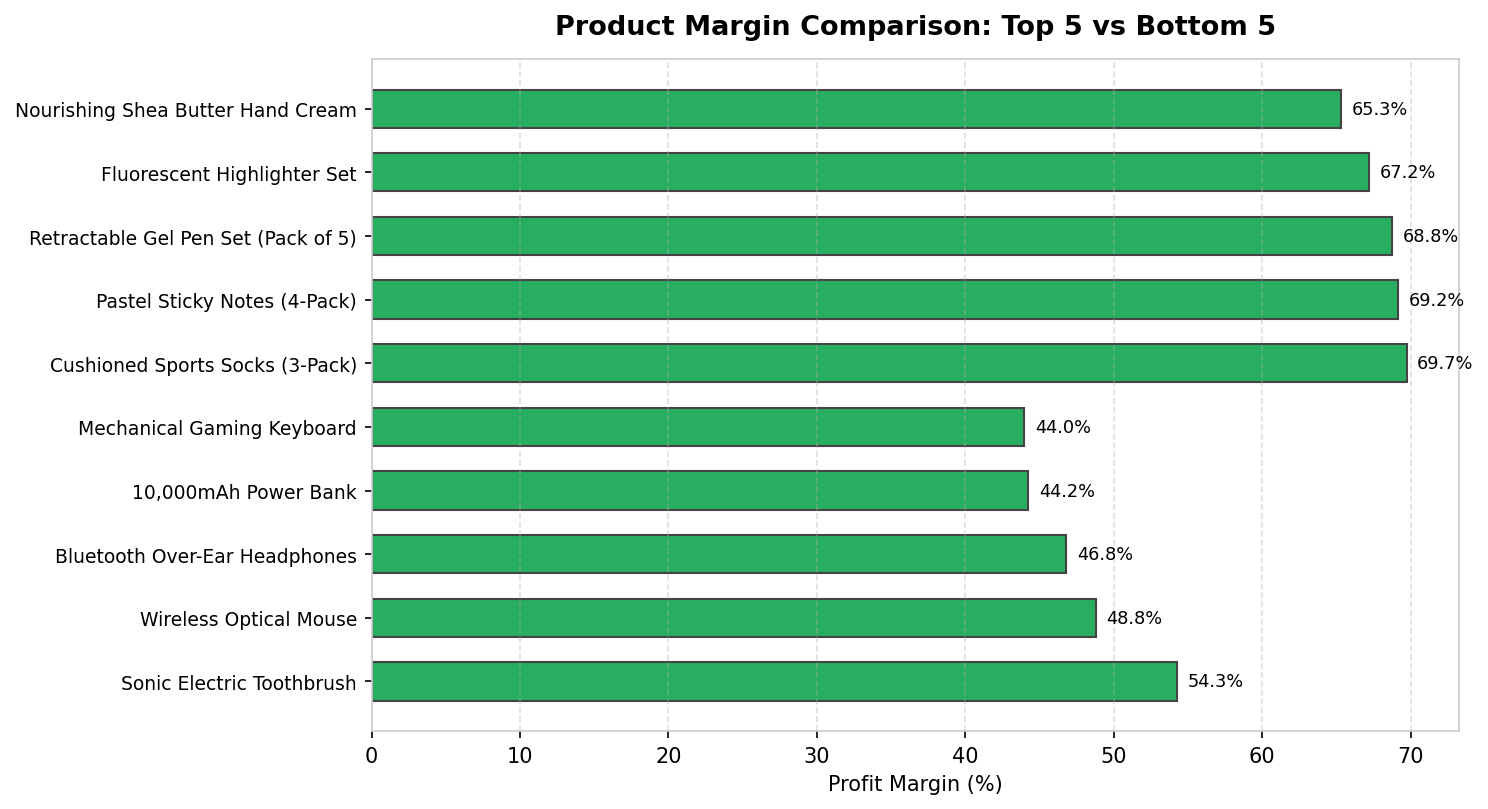

In [14]:
# Chart 4: Top 5 vs Bottom 5 Products by Profit Margin
top_5 = prod_perf.head(5).copy()
bottom_5 = prod_perf.tail(5).copy()
combined_ranked = pd.concat([bottom_5, top_5]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

y_pos = np.arange(len(combined_ranked))
colors = ["#e74c3c" if m < 35 else "#27ae60" for m in combined_ranked['Margin_Pct']]

bars = ax.barh(y_pos, combined_ranked['Margin_Pct'], color=colors, height=0.6, edgecolor="#444444")

ax.set_yticks(y_pos)
ax.set_yticklabels(combined_ranked['Product_Name'], fontsize=9)
ax.set_xlabel("Profit Margin (%)", fontsize=10)
ax.set_title("Product Margin Comparison: Top 5 vs Bottom 5", fontsize=13, fontweight="bold", pad=12)
ax.grid(axis="x", linestyle="--", alpha=0.4)

for bar, margin in zip(bars, combined_ranked['Margin_Pct']):
    w = bar.get_width()
    ax.annotate(f"{margin:.1f}%",
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()


### 9. Business Recommendations
1. **Limit Discounts to 15-20%:** Discounts above 20% severely erode profit margins (dropping margins from ~55% down to under 25%).
2. **Promote High-Margin Products:** Stationery and Personal Care deliver consistent margins over 50% with low return rates.
3. **Renegotiate Cost on Electronics:** Electronics drives large revenue but has thinner margins (~35%) due to high procurement costs.
4. **Reduce Apparel Returns:** Apparel has the highest return rate (~8.5%). Better sizing information can reduce return friction.
